In [ ]:
import os
import logging
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
rejected_df = pl.read_parquet("../data/processed_data/processed_rejected_df.parquet")
rejected_df.head()

## Step 3: Exploratory Data Analysis (EDA)
This section is organized into Univariate (single variable), Bivariate (two variables), and Multivariate (complex interactions) analysis to understand the profile of rejected loans.

### 3.1 Univariate Analysis
Understanding the distribution of individual features. This helps identify skewness, outliers, and common values.

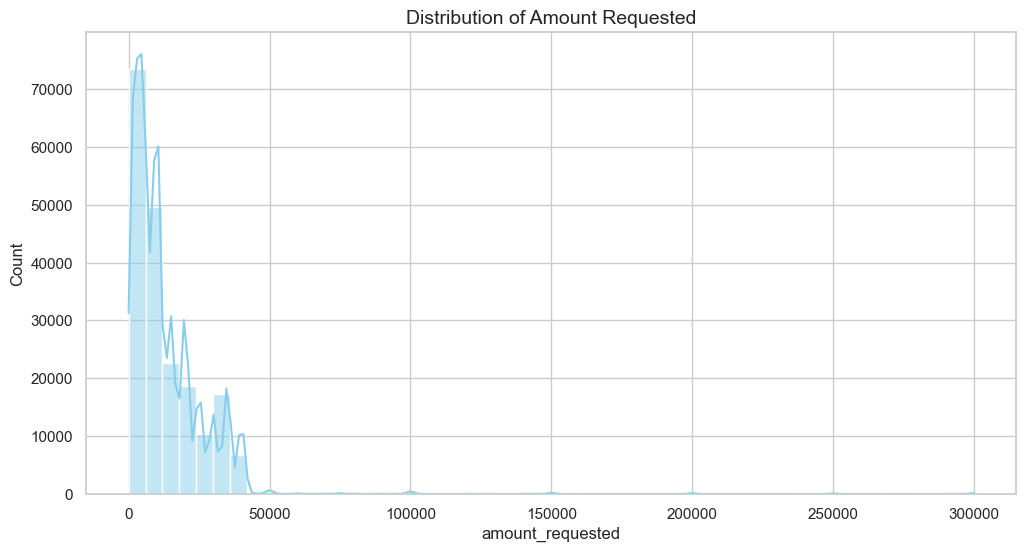

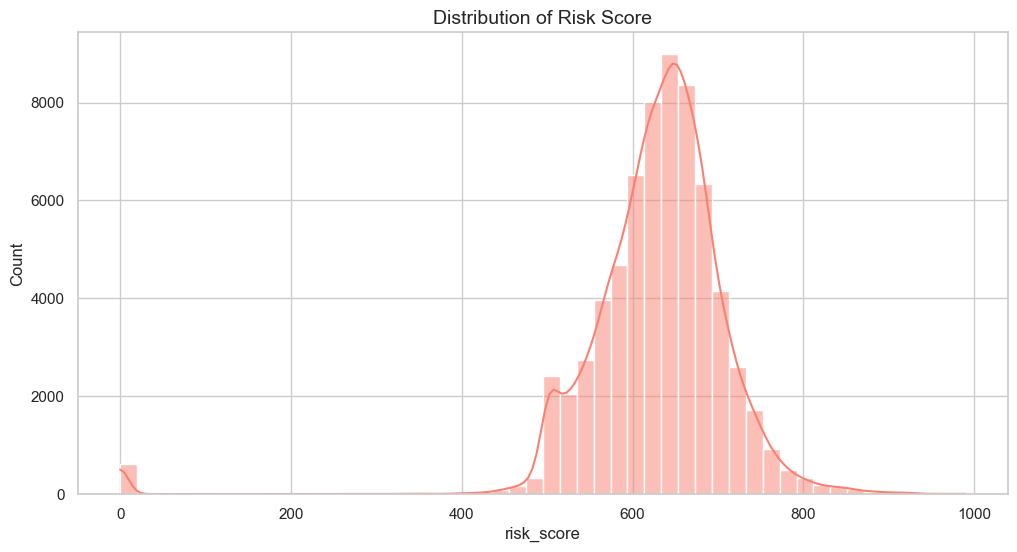

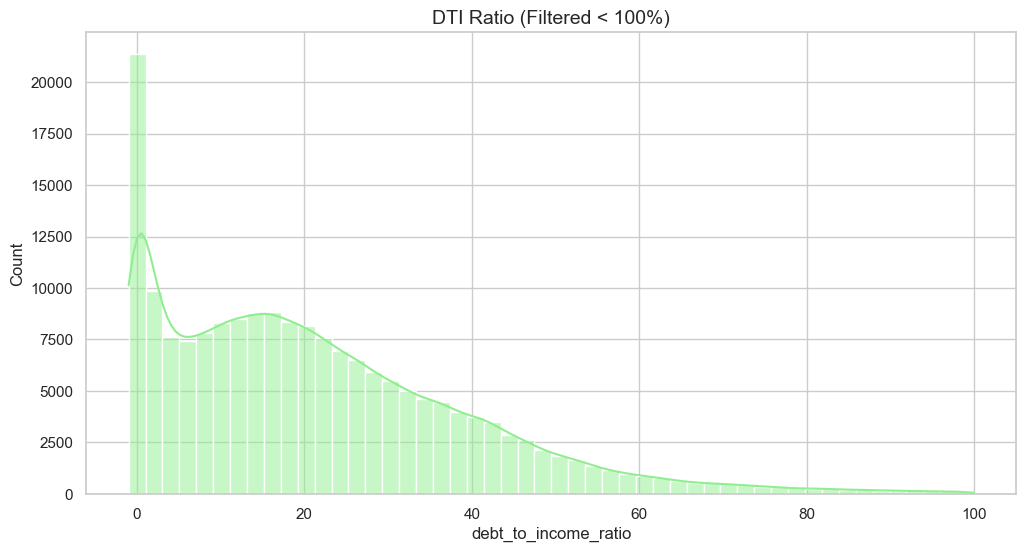

2026-05-03 12:43:05,453 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-05-03 12:43:05,547 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


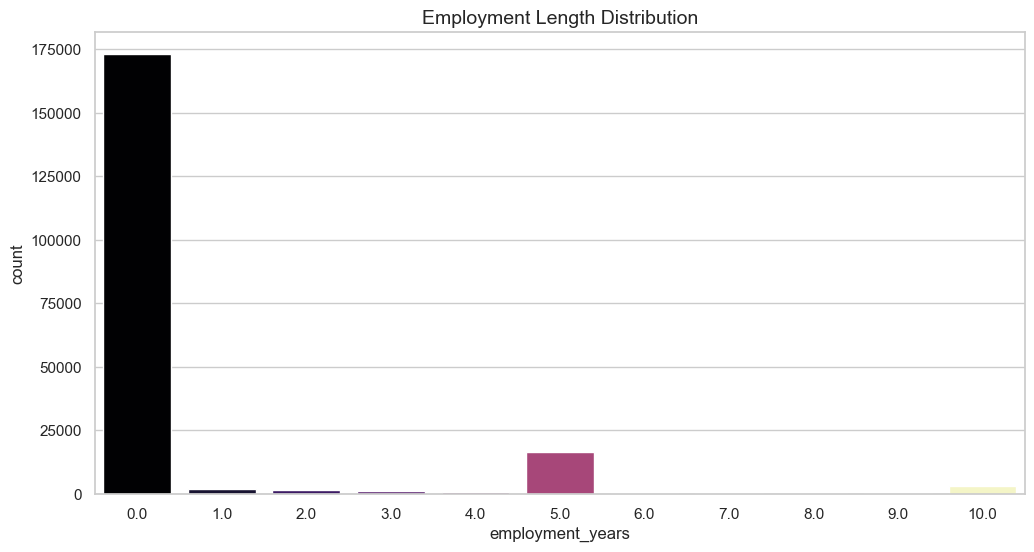


--- Statistical Summary ---


,amount_requested,application_date,risk_score,debt_to_income_ratio,policy_code,employment_years
count,200000.000000,200000,66045.000000,200000.000000,199991.000000,200000.000000
mean,13076.209425,2017-01-08 09:13:16.176000,628.391672,141.426850,0.006120,0.688535
min,0.000000,2007-05-29 00:00:00,0.000000,-1.000000,0.000000,0.000000
25%,4600.000000,2016-02-28 00:00:00,591.000000,8.050000,0.000000,0.000000
50%,10000.000000,2017-06-17 00:00:00,637.000000,19.950000,0.000000,0.000000
75%,20000.000000,2018-04-30 00:00:00,675.000000,36.640000,0.000000,0.000000
max,300000.000000,2018-12-31 00:00:00,990.000000,968400.000000,2.000000,10.000000
std,14588.757562,NaN,89.854291,3542.906283,0.110468,1.934994


In [ ]:
if 'rejected_df' in locals() and not rejected_df.empty:
    # Amount Requested
    plt.figure(figsize=(12, 6))
    sns.histplot(rejected_df['amount_requested'], bins=50, kde=True, color='skyblue')
    plt.title('Distribution of Amount Requested')
    plt.show()
    
    # Risk Score
    plt.figure(figsize=(12, 6))
    sns.histplot(rejected_df['risk_score'].dropna(), bins=50, kde=True, color='salmon')
    plt.title('Distribution of Risk Score')
    plt.show()
    
    # DTI Ratio
    plt.figure(figsize=(12, 6))
    dti_filtered = rejected_df[rejected_df['debt_to_income_ratio'] < 100]['debt_to_income_ratio']
    sns.histplot(dti_filtered, bins=50, kde=True, color='lightgreen')
    plt.title('DTI Ratio (Filtered < 100%)')
    plt.show()
    
    # Employment Years
    plt.figure(figsize=(12, 6))
    sns.countplot(data=rejected_df, x='employment_years', palette='magma', hue='employment_years', legend=False)
    plt.title('Employment Length Distribution')
    plt.show()
    
    # Summary Statistics for quick peek
    print("\n--- Statistical Summary ---")
    display(rejected_df.describe())

### 3.2 Bivariate Analysis
Investigating the relationship between two variables. We want to see how features like `risk_score` or `employment_years` influence the `amount_requested`.

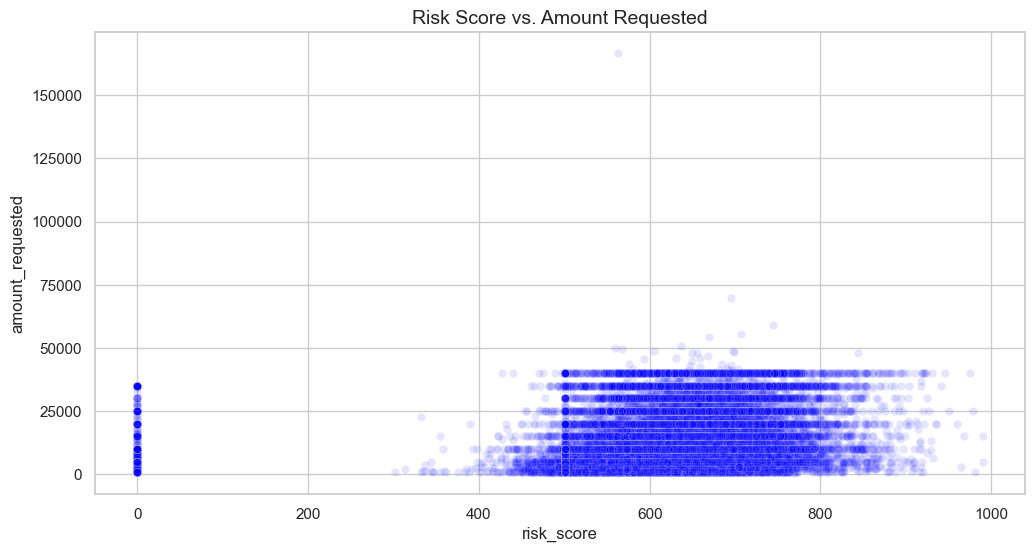

2026-05-03 12:43:06,325 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-05-03 12:43:06,410 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


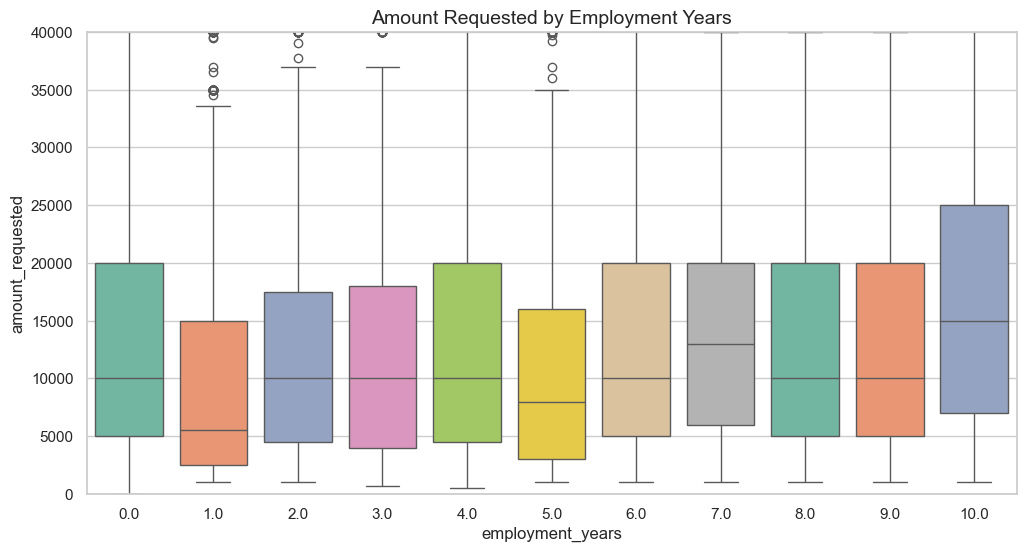

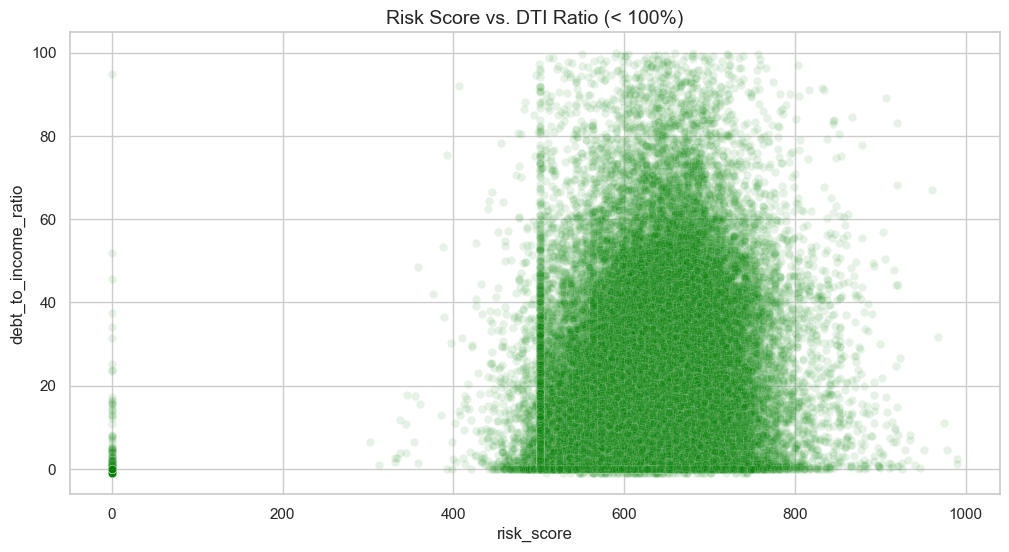

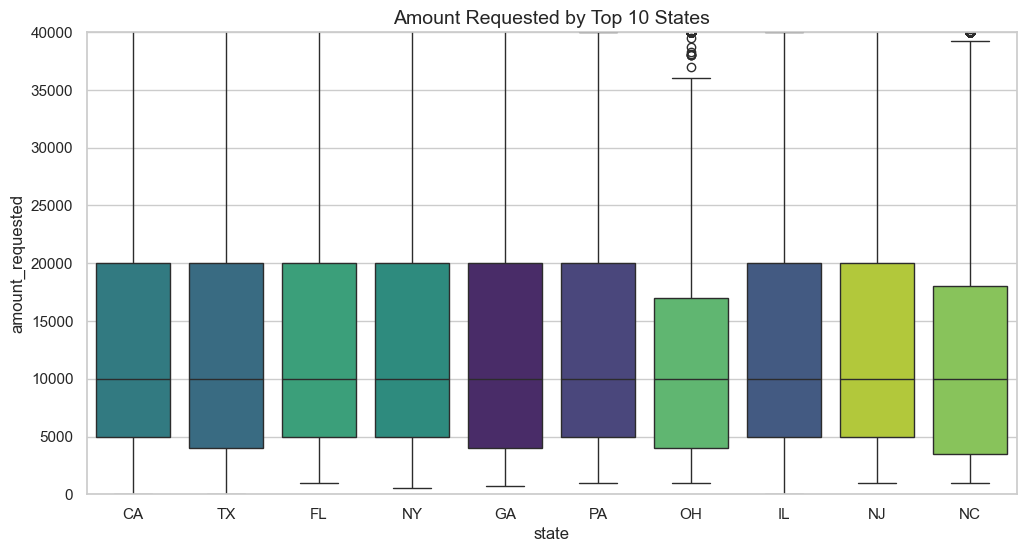

In [ ]:
if 'rejected_df' in locals() and not rejected_df.empty:
    # 1. Risk Score vs Amount Requested (Numerical vs Numerical)
    plt.figure(figsize=(12, 6))
    sns.scatterplot(data=rejected_df, x='risk_score', y='amount_requested', alpha=0.1, color='blue')
    plt.title('Risk Score vs. Amount Requested')
    plt.show()
    
    # 2. Amount Requested by Employment Years (Categorical/Discrete vs Numerical)
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=rejected_df, x='employment_years', y='amount_requested', palette='Set2', hue='employment_years', legend=False)
    plt.title('Amount Requested by Employment Years')
    plt.ylim(0, 40000) # Zooming in on the bulk of the data
    plt.show()
    
    # 3. Risk Score vs Debt-to-Income Ratio (Numerical vs Numerical)
    plt.figure(figsize=(12, 6))
    dti_lim = rejected_df[rejected_df['debt_to_income_ratio'] < 100]
    sns.scatterplot(data=dti_lim, x='risk_score', y='debt_to_income_ratio', alpha=0.1, color='green')
    plt.title('Risk Score vs. DTI Ratio (< 100%)')
    plt.show()
    
    # 4. Amount Requested by State (Top 10) (Categorical vs Numerical)
    plt.figure(figsize=(12, 6))
    top_states = rejected_df['state'].value_counts().nlargest(10).index
    sns.boxplot(data=rejected_df[rejected_df['state'].isin(top_states)], 
                x='state', y='amount_requested', order=top_states, palette='viridis', hue='state', legend=False)
    plt.title('Amount Requested by Top 10 States')
    plt.ylim(0, 40000)
    plt.show()

### 3.3 Multivariate Analysis
Exploring interactions between multiple variables simultaneously to identify complex patterns.

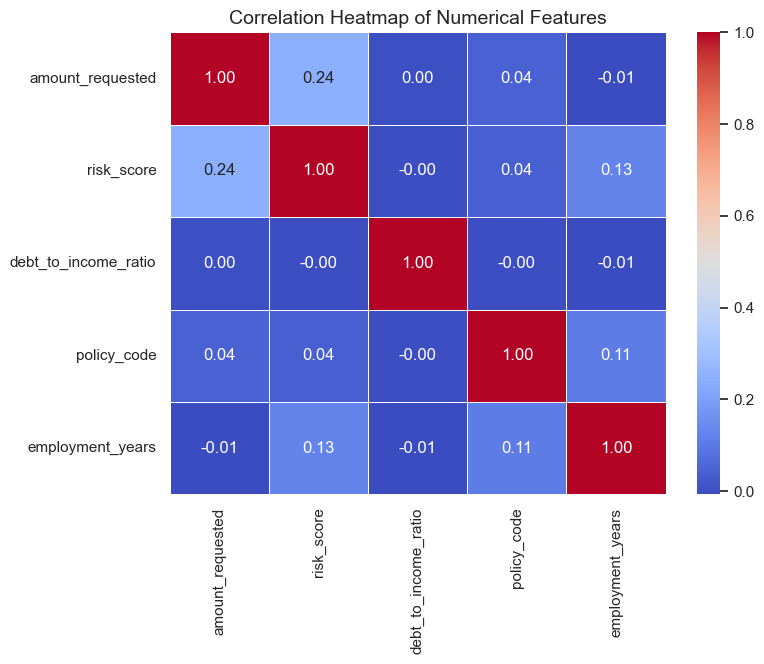

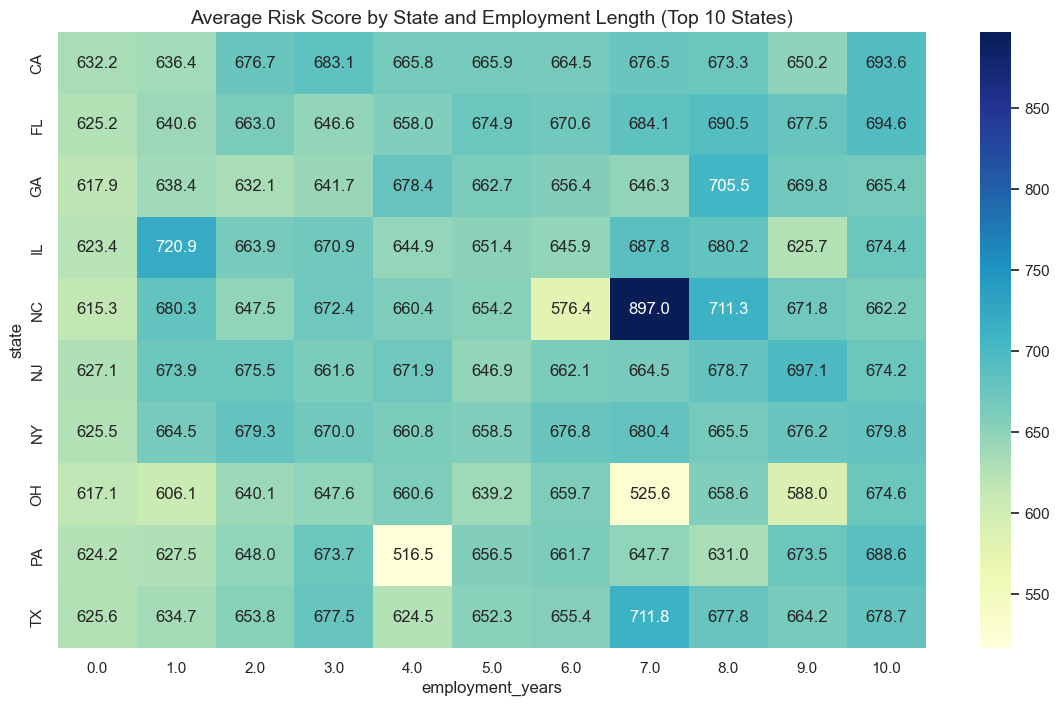

In [ ]:
if 'rejected_df' in locals() and not rejected_df.empty:
    # 1. Correlation Heatmap
    plt.figure(figsize=(8, 6))
    numeric_cols = rejected_df.select_dtypes(include=[np.number])
    sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
    plt.title('Correlation Heatmap of Numerical Features')
    plt.show()
    
    # 2. Heatmap: Mean Risk Score by State and Employment Years (Multivariate)
    plt.figure(figsize=(14, 8))
    top_10_states = rejected_df['state'].value_counts().nlargest(10).index
    subset = rejected_df[rejected_df['state'].isin(top_10_states)]
    
    # Pivot table for the heatmap
    pivot_table = subset.pivot_table(values='risk_score', index='state', columns='employment_years', aggfunc='mean')
    
    sns.heatmap(pivot_table, annot=True, cmap='YlGnBu', fmt=".1f")
    plt.title('Average Risk Score by State and Employment Length (Top 10 States)')
    plt.show()

### 3.4 Temporal Analysis
Looking at trends over time to identify seasonality or growth in rejection volume.

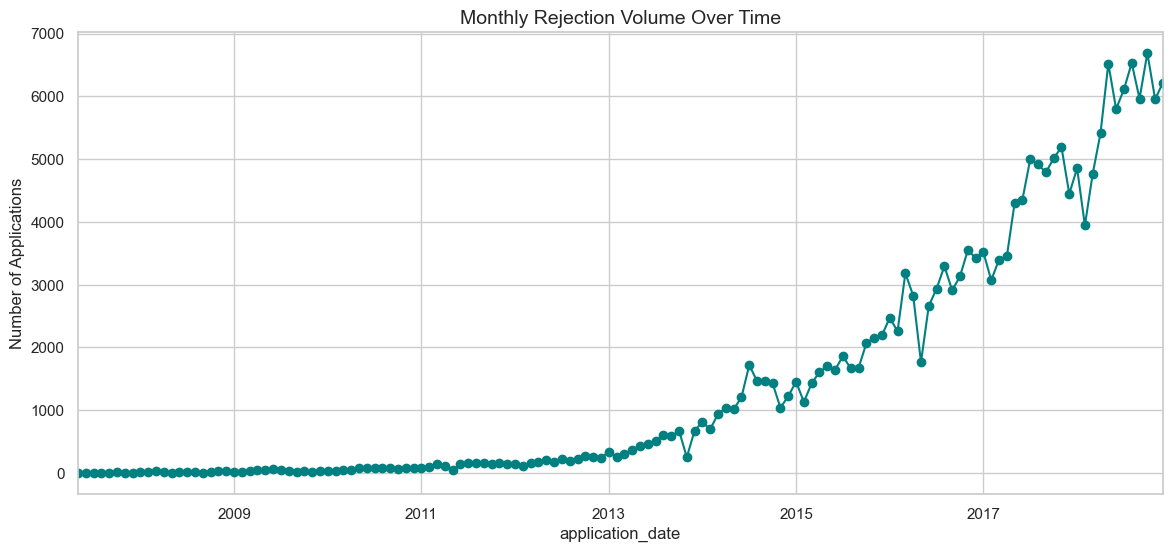

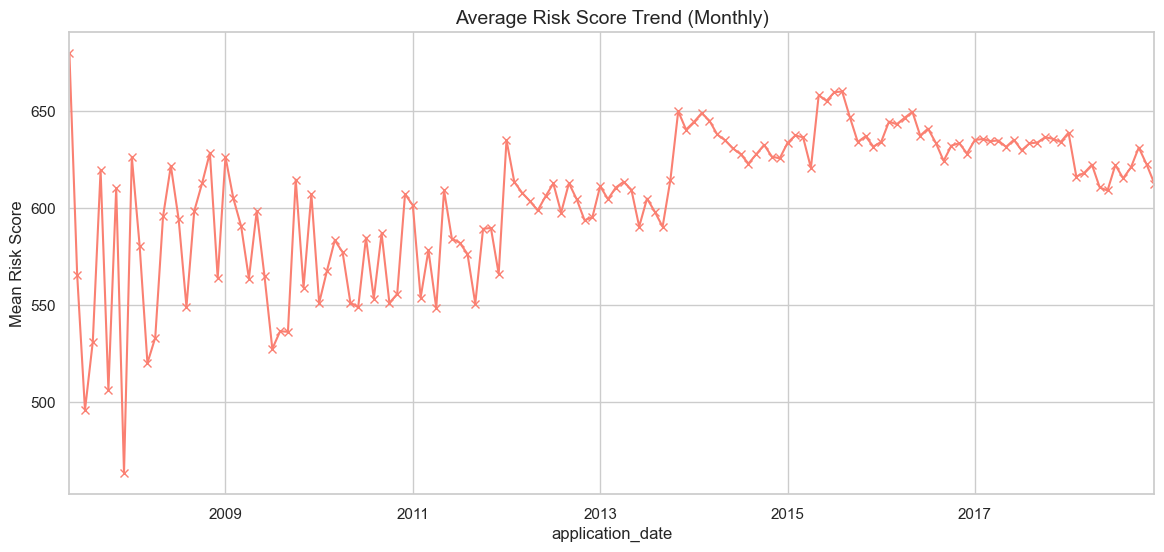

In [ ]:
if 'rejected_df' in locals() and not rejected_df.empty:
    # Application volume over time
    plt.figure(figsize=(14, 6))
    rejected_df.set_index('application_date').resample('ME').size().plot(color='teal', marker='o')
    plt.title('Monthly Rejection Volume Over Time')
    plt.ylabel('Number of Applications')
    plt.show()
    
    # Average Risk Score over time (Multivariate Temporal)
    plt.figure(figsize=(14, 6))
    rejected_df.set_index('application_date').resample('ME')['risk_score'].mean().plot(color='salmon', marker='x')
    plt.title('Average Risk Score Trend (Monthly)')
    plt.ylabel('Mean Risk Score')
    plt.show()